# Handwritten Digit Recognition
**YASH SHUKLA | 210911380 | Individual project**
GitHub profile: https://github.com/yashshukla27
MLP and CNN are implemented; LSTM is planned for final.

In [8]:
%pip -q install "numpy<2.3" scikit-learn==1.8.0 matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 55.4 MB/s eta 0:00:00


## 1 Load the training implementation
The code below defines the dataset split, neural networks, gradients and training loop.

In [2]:
%%writefile train.py
"""Two end-to-end neural networks, implemented in NumPy.
AI assistance: ChatGPT generated the initial implementation; see START_HERE.txt.
Run: python train.py --epochs 40
"""
import argparse, copy, csv, json, platform, time
from pathlib import Path
import numpy as np
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

class MLP:
    def __init__(self, seed=42):
        r=np.random.default_rng(seed)
        self.p={'w1':r.normal(0,np.sqrt(2/64),(64,64)), 'b1':np.zeros(64),
                'w2':r.normal(0,np.sqrt(2/64),(64,32)), 'b2':np.zeros(32),
                'w3':r.normal(0,np.sqrt(2/32),(32,10)), 'b3':np.zeros(10)}
    def forward(self,x):
        p=self.p; self.x=x.reshape(-1,64)
        self.h1=np.maximum(0,self.x@p['w1']+p['b1'])
        self.h2=np.maximum(0,self.h1@p['w2']+p['b2'])
        return self.h2@p['w3']+p['b3']
    def backward(self,d):
        p=self.p; g={'w3':self.h2.T@d,'b3':d.sum(0)}
        d=(d@p['w3'].T)*(self.h2>0)
        g.update(w2=self.h1.T@d,b2=d.sum(0))
        d=(d@p['w2'].T)*(self.h1>0)
        g.update(w1=self.x.T@d,b1=d.sum(0)); return g

class CNN:
    """Valid 3x3 convolution (8 filters), ReLU, flatten, dense32, dense10.
    Every convolution filter is trained by backpropagation, not fixed.
    """
    def __init__(self,seed=42):
        r=np.random.default_rng(seed)
        self.p={'k':r.normal(0,np.sqrt(2/9),(9,8)), 'bc':np.zeros(8),
                'w1':r.normal(0,np.sqrt(2/288),(288,32)), 'b1':np.zeros(32),
                'w2':r.normal(0,np.sqrt(2/32),(32,10)), 'b2':np.zeros(10)}
    def forward(self,x):
        p=self.p; n=len(x)
        self.patches=np.lib.stride_tricks.sliding_window_view(x,(3,3),axis=(1,2)).reshape(n,36,9)
        self.conv=np.maximum(0,self.patches@p['k']+p['bc'])
        self.flat=self.conv.reshape(n,288)
        self.h=np.maximum(0,self.flat@p['w1']+p['b1'])
        return self.h@p['w2']+p['b2']
    def backward(self,d):
        p=self.p; g={'w2':self.h.T@d,'b2':d.sum(0)}
        d=(d@p['w2'].T)*(self.h>0)
        g.update(w1=self.flat.T@d,b1=d.sum(0))
        d=(d@p['w1'].T).reshape(-1,36,8)*(self.conv>0)
        g.update(k=np.einsum('npi,npf->if',self.patches,d),bc=d.sum((0,1)))
        return g

def softmax(z):
    z=z-z.max(1,keepdims=True); p=np.exp(z); return p/p.sum(1,keepdims=True)

def loss_grad(z,y):
    p=softmax(z); loss=-np.log(p[np.arange(len(y)),y]+1e-12).mean()
    p[np.arange(len(y)),y]-=1
    return float(loss),p/len(y)

def prepare(seed=42):
    d=load_digits(); x=d.images.astype(np.float64)/16.0; y=d.target
    ids=np.arange(len(y))
    tr,rest=train_test_split(ids,test_size=.30,stratify=y,random_state=seed)
    va,te=train_test_split(rest,test_size=.50,stratify=y[rest],random_state=seed)
    assert not (set(tr)&set(va) or set(tr)&set(te) or set(va)&set(te))
    return x,y,tr,va,te

def train(epochs=40,out='results',seed=42):
    out=Path(out); out.mkdir(exist_ok=True,parents=True)
    x,y,tr,va,te=prepare(seed)
    np.savez(out/'split_indices.npz',train=tr,validation=va,test=te)
    rows=[]; histories={}
    for name,cls in [('MLP',MLP),('CNN',CNN)]:
        model=cls(seed); rng=np.random.default_rng(seed)
        m={k:np.zeros_like(v) for k,v in model.p.items()}; v=copy.deepcopy(m)
        step=0; best=-1; best_epoch=0; hist=[]; start=time.perf_counter()
        for epoch in range(1,epochs+1):
            order=rng.permutation(tr); total=0
            for i in range(0,len(order),64):
                batch=order[i:i+64]
                loss,d=loss_grad(model.forward(x[batch]),y[batch]); g=model.backward(d)
                step+=1; total+=loss*len(batch)
                for k in model.p:
                    m[k]=.9*m[k]+.1*g[k]; v[k]=.999*v[k]+.001*g[k]**2
                    model.p[k]-=.001*(m[k]/(1-.9**step))/(np.sqrt(v[k]/(1-.999**step))+1e-8)
            val=float(accuracy_score(y[va],model.forward(x[va]).argmax(1)))
            hist.append({'epoch':epoch,'train_loss':total/len(tr),'val_accuracy':val})
            if val>best:
                best=val; best_epoch=epoch; checkpoint=copy.deepcopy(model.p)
            if epoch%10==0: print(name,epoch,'validation',round(val,4),flush=True)
        seconds=time.perf_counter()-start; model.p=checkpoint
        pred=model.forward(x[te]).argmax(1)
        pr,re,f1,_=precision_recall_fscore_support(y[te],pred,average='macro',zero_division=0)
        row=dict(model=name,parameters=sum(a.size for a in model.p.values()),best_epoch=best_epoch,
                 validation_accuracy=best,test_accuracy=float(accuracy_score(y[te],pred)),
                 macro_precision=float(pr),macro_recall=float(re),macro_f1=float(f1),training_seconds=seconds)
        rows.append(row); histories[name]=hist
        np.savez(out/f'{name}_weights.npz',**model.p)
        np.savetxt(out/f'{name}_confusion.csv',confusion_matrix(y[te],pred),fmt='%d',delimiter=',')
        with (out/f'{name}_predictions.csv').open('w') as f:
            w=csv.writer(f); w.writerow(['dataset_index','true_digit','predicted_digit'])
            w.writerows(zip(te,y[te],pred))
        print(row,flush=True)
    payload={'created_utc':__import__('datetime').datetime.now(__import__('datetime').timezone.utc).isoformat(),
             'seed':seed,'epochs':epochs,'batch_size':64,'learning_rate':.001,
             'split_sizes':{'train':len(tr),'validation':len(va),'test':len(te)},
             'python':platform.python_version(),'numpy':np.__version__,'sklearn':sklearn.__version__,
             'platform':platform.platform(),'results':rows}
    (out/'metrics.json').write_text(json.dumps(payload,indent=2))
    (out/'history.json').write_text(json.dumps(histories,indent=2))
    with (out/'comparison.csv').open('w') as f:
        w=csv.DictWriter(f,fieldnames=rows[0]); w.writeheader(); w.writerows(rows)
    return payload

if __name__=='__main__':
    a=argparse.ArgumentParser(); a.add_argument('--epochs',type=int,default=40)
    a.add_argument('--out',default='results'); a.add_argument('--seed',type=int,default=42)
    args=a.parse_args(); train(args.epochs,args.out,args.seed)


Writing train.py


In [3]:
%%writefile check_gradients.py
"""Check analytical backpropagation against finite differences before training."""
import numpy as np
from train import MLP,CNN,loss_grad
for cls in [MLP,CNN]:
    model=cls(); rng=np.random.default_rng(23)
    x=rng.random((4,8,8)); y=np.array([1,3,5,7])
    _,d=loss_grad(model.forward(x),y); grads=model.backward(d)
    maximum=0
    for k,p in model.p.items():
        for _ in range(5):
            ix=tuple(rng.integers(n) for n in p.shape); old=p[ix]; eps=1e-5
            p[ix]=old+eps; hi=loss_grad(model.forward(x),y)[0]
            p[ix]=old-eps; lo=loss_grad(model.forward(x),y)[0]; p[ix]=old
            err=abs((hi-lo)/(2*eps)-grads[k][ix]); maximum=max(maximum,err)
    assert maximum<1e-5,(cls.__name__,maximum)
    print(cls.__name__,'gradient check PASS; max absolute error',maximum)


Writing check_gradients.py


## 2 Check the gradients
A gradient tells the model how to change a weight to reduce its mistakes. Numerical checks help catch implementation errors.

In [4]:
!python check_gradients.py

MLP gradient check PASS; max absolute error 4.95252172605376e-11
CNN gradient check PASS; max absolute error 2.7883279019036422e-11


## 3 Train and evaluate
Training learns from 1,257 images. Validation selects checkpoints using 270 images. A separate 270-image test set measures the final result.

In [11]:
import subprocess
import json
from pathlib import Path

# Run training in a separate clean Python process to avoid in-memory C-extension package conflicts
result = subprocess.run(
    ["python", "train.py", "--epochs", "40"],
    capture_output=True,
    text=True
)

# Display outputs
print(result.stdout)
if result.stderr:
    print("Errors (if any):", result.stderr)

# Load and display metrics if successfully created
metrics_path = Path("results/metrics.json")
if metrics_path.exists():
    with open(metrics_path, "r") as f:
        metrics = json.load(f)
else:
    metrics = "Error: results/metrics.json was not created."
metrics

MLP 10 validation 0.937
MLP 20 validation 0.9519
MLP 30 validation 0.9593
MLP 40 validation 0.9556
{'model': 'MLP', 'parameters': 6570, 'best_epoch': 28, 'validation_accuracy': 0.9592592592592593, 'test_accuracy': 0.9666666666666667, 'macro_precision': 0.9681538461538463, 'macro_recall': 0.9663715913715916, 'macro_f1': 0.9667156140955168, 'training_seconds': 0.3796791900001608}
CNN 10 validation 0.9407
CNN 20 validation 0.9593
CNN 30 validation 0.9556
CNN 40 validation 0.9667
{'model': 'CNN', 'parameters': 9658, 'best_epoch': 33, 'validation_accuracy': 0.9703703703703703, 'test_accuracy': 0.9777777777777777, 'macro_precision': 0.9785582010582011, 'macro_recall': 0.9773402523402523, 'macro_f1': 0.9776207784402511, 'training_seconds': 1.1239265039998827}



{'created_utc': '2026-10-02T21:02:51.022397+00:00',
 'seed': 42,
 'epochs': 40,
 'batch_size': 64,
 'learning_rate': 0.001,
 'split_sizes': {'train': 1257, 'validation': 270, 'test': 270},
 'python': '3.13.15',
 'numpy': '2.2.6',
 'sklearn': '1.8.0',
 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39',
 'results': [{'model': 'MLP',
   'parameters': 6570,
   'best_epoch': 28,
   'validation_accuracy': 0.9592592592592593,
   'test_accuracy': 0.9666666666666667,
   'macro_precision': 0.9681538461538463,
   'macro_recall': 0.9663715913715916,
   'macro_f1': 0.9667156140955168,
   'training_seconds': 0.3796791900001608},
  {'model': 'CNN',
   'parameters': 9658,
   'best_epoch': 33,
   'validation_accuracy': 0.9703703703703703,
   'test_accuracy': 0.9777777777777777,
   'macro_precision': 0.9785582010582011,
   'macro_recall': 0.9773402523402523,
   'macro_f1': 0.9776207784402511,
   'training_seconds': 1.1239265039998827}]}

## 4 Inspect predictions
Actual is the dataset label. Predicted is the CNN answer.

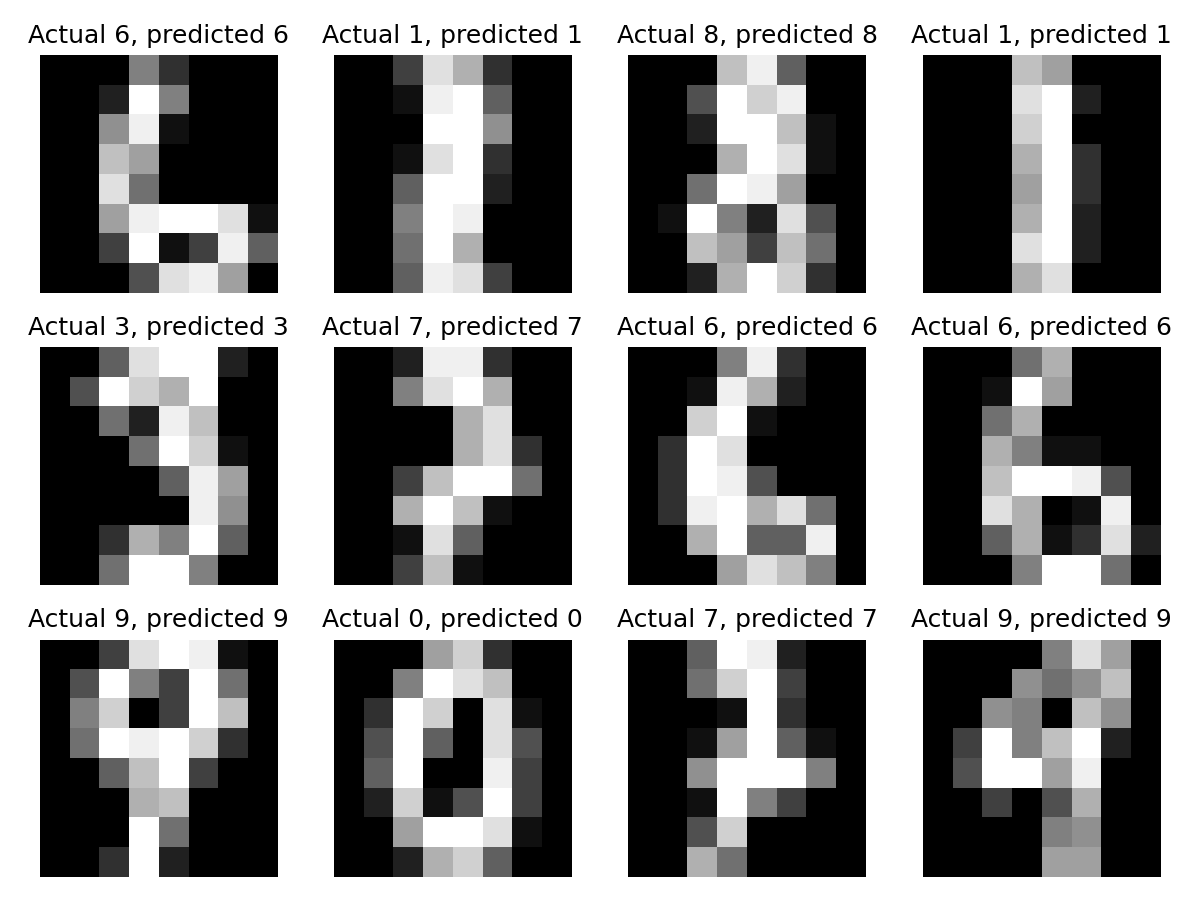

In [13]:
import subprocess
from IPython.display import Image, display

# Create a script to generate the plot in a clean external Python process
with open('plot_results.py', 'w') as f:
    f.write('''
import numpy as np
import matplotlib.pyplot as plt
from train import prepare, CNN

x, y, tr, va, te = prepare()
model = CNN()
model.p = dict(np.load("results/CNN_weights.npz"))
pred = model.forward(x[te]).argmax(1)

fig, axs = plt.subplots(3, 4, figsize=(8, 6))
for ax, i, p in zip(axs.flat, te[:12], pred[:12]):
    ax.imshow(x[i], cmap="gray")
    ax.set_title(f"Actual {y[i]}, predicted {p}")
    ax.axis("off")
plt.tight_layout()
plt.savefig("results/predictions_plot.png", dpi=150)
''')

# Run the plotting script
result = subprocess.run(["python", "plot_results.py"], capture_output=True, text=True)
if result.stderr:
    print("Errors during plotting:", result.stderr)
else:
    # Display the generated plot image
    display(Image(filename="results/predictions_plot.png"))


## 5 Download evidence
Keep your own output and add your actual contribution to the task log.

In [14]:
import os
import shutil

# Ensure the results directory exists to prevent archiving errors
os.makedirs('results', exist_ok=True)

shutil.make_archive('my_experiment_results', 'zip', 'results')
try:
    from google.colab import files
    files.download('my_experiment_results.zip')
except ImportError:
    print('Saved my_experiment_results.zip in the current folder.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>